# MLT Task 2
Natalya Makushkina

# Preprocessing

In [17]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

import math
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score

In [18]:
df = pd.read_csv("fma_dataset_filtered.csv")
display(df.head())
display(df.shape)

print("\nData types:")
display(df.dtypes.value_counts())

print("\nNans:")
nan_counts = df.isna().sum()
display(nan_counts[nan_counts > 0])

print("\nGenres:")
display(df['genre'].value_counts())

print("\nColumns:")
display(df.columns.values.tolist()[:10])

,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593,2.691455,0.866868,...,0.085629,0.071289,0.000000,2.089872,0.061448,168,165.922,0.675894,0.634476,Hip-Hop
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848,1.054094,0.108103,...,0.084578,0.063965,0.000000,1.716724,0.069330,237,126.957,0.528643,0.817461,Hip-Hop
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192,-0.927232,0.666617,...,0.053114,0.041504,0.000000,2.193303,0.044861,206,100.260,0.745566,0.701470,Hip-Hop
3,134,0.918445,0.674147,0.577818,1.281117,0.933746,0.078177,1.199204,-0.175223,0.925482,...,0.064370,0.050781,0.000000,1.806106,0.054623,207,114.290,0.513238,0.560410,Hip-Hop
4,139,-0.020869,0.432330,0.331278,0.829845,2.625593,2.005660,0.907704,0.748191,1.560385,...,0.070760,0.066895,0.000977,0.769163,0.030017,296,196.961,0.260911,0.607067,Folk


(2406, 524)


Data types:


float64    521
int64        2
str          1
Name: count, dtype: int64


Nans:


Series([], dtype: int64)


Genres:


genre
Hip-Hop                910
Folk                   874
Old-Time / Historic    357
Classical              265
Name: count, dtype: int64


Columns:


['track_id',
 'chroma_cens_kurtosis_01',
 'chroma_cens_kurtosis_02',
 'chroma_cens_kurtosis_03',
 'chroma_cens_kurtosis_04',
 'chroma_cens_kurtosis_05',
 'chroma_cens_kurtosis_06',
 'chroma_cens_kurtosis_07',
 'chroma_cens_kurtosis_08',
 'chroma_cens_kurtosis_09']

In [19]:
print("\nDuplicates:")
display(df.duplicated().sum())


Duplicates:


np.int64(0)

In [20]:
display(df["track_id"].head())
display(df["duration"].head())

0      2
1      3
2      5
3    134
4    139
Name: track_id, dtype: int64

0    168
1    237
2    206
3    207
4    296
Name: duration, dtype: int64

In [21]:

print("\nInfinite values:")
mask = df.select_dtypes(include=[np.number]).apply(lambda col: np.isinf(col)).any(axis=1)
display(df[mask])


Infinite values:


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,...,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy,genre


In [22]:
print("\nConstant values:")
constant_cols = df.columns[df.nunique(dropna=True) == 1].tolist()
display(constant_cols)



Constant values:


['chroma_stft_max_04',
 'chroma_stft_max_05',
 'chroma_stft_max_07',
 'chroma_stft_max_10']

In [23]:
# Drop columns with constant values
x = df.iloc[:, 1:-1]
x = x.drop(columns=constant_cols)
y = df.iloc[:, -1]
feature_names = x.columns

# z-scaling
x_stand_scaled = StandardScaler().fit_transform(x)
x_stand_scaled = pd.DataFrame(x_stand_scaled, columns=feature_names)

print(x_stand_scaled.shape)
print(y.shape)
x_stand_scaled.head()

(2406, 518)
(2406,)


,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07,chroma_cens_kurtosis_08,chroma_cens_kurtosis_09,chroma_cens_kurtosis_10,...,zcr_max_01,zcr_mean_01,zcr_median_01,zcr_min_01,zcr_skew_01,zcr_std_01,duration,tempo,danceability,energy
0,3.763350,4.802694,0.149462,1.294600,0.935749,0.500832,1.245515,1.904060,0.683259,1.111415,...,0.552435,1.109582,1.011679,-0.516662,-0.469370,1.021568,-0.312745,1.382178,0.995706,1.130052
1,0.965237,0.762063,0.213381,2.157781,1.044804,0.097596,1.152987,0.752128,0.127183,0.544318,...,0.593891,1.076329,0.764091,-0.516662,-0.600209,1.347216,-0.023610,0.332919,0.205530,1.855755
2,0.245363,0.004344,-0.202802,0.691804,1.225047,0.804679,-0.693649,-0.641793,0.536501,0.873686,...,0.040158,0.080782,0.004823,-0.516662,-0.433103,0.336255,-0.153511,-0.385984,1.369578,1.395743
3,0.452051,0.683965,0.368239,1.234021,0.586925,0.106799,1.017803,-0.112733,0.726215,1.187818,...,0.309621,0.436910,0.318434,-0.516662,-0.568869,0.739583,-0.149321,-0.008181,0.122864,0.836310
4,-0.044634,0.465364,0.204045,0.822944,1.662418,1.782664,0.782744,0.536916,1.191516,2.073156,...,-0.649788,0.639106,0.863126,-0.328258,-0.932458,-0.277027,0.223622,2.218004,-1.231169,1.021348


# Visualising with PCA, t-SNE

In [24]:
pca_model = PCA(n_components=2)
pca = pca_model.fit_transform(x_stand_scaled)
pca = pd.DataFrame(pca, columns=['pc_1', 'pc_2'])
pca.head()

,pc_1,pc_2
0,-7.685345,-0.759405
1,-10.188710,1.699750
2,-6.898330,1.583589
3,-8.947767,3.961536
4,-5.512513,-4.259653


In [25]:
pca.shape

(2406, 2)

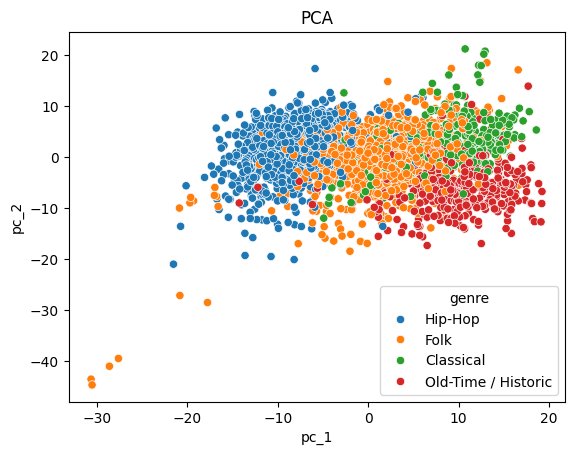

In [26]:
sns.scatterplot(x ='pc_1', y = 'pc_2', data=pca, hue=y)
plt.title('PCA')
plt.show()

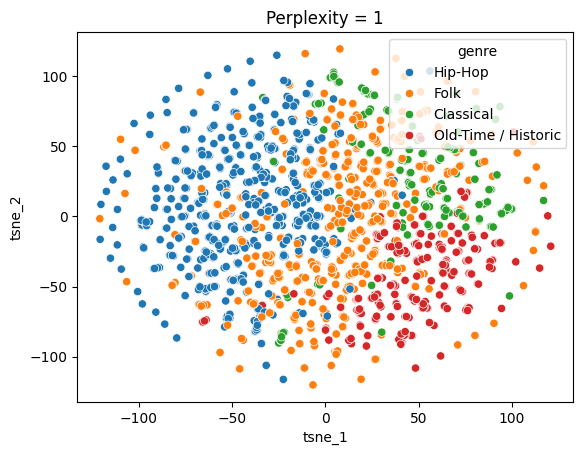

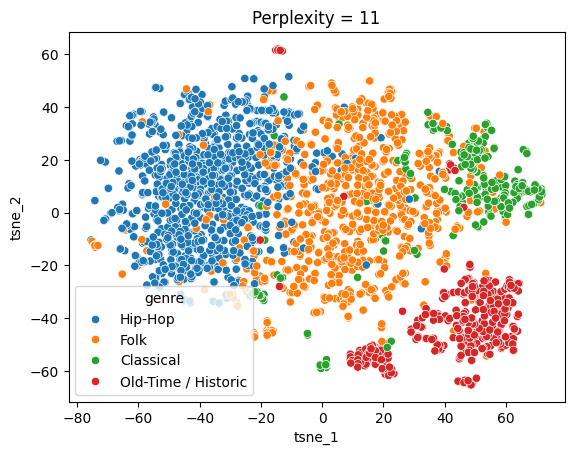

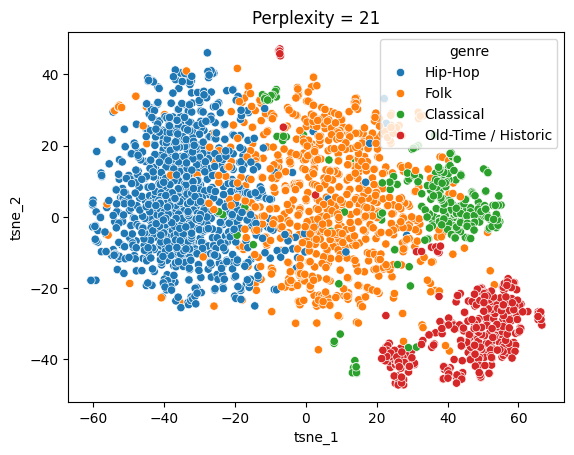

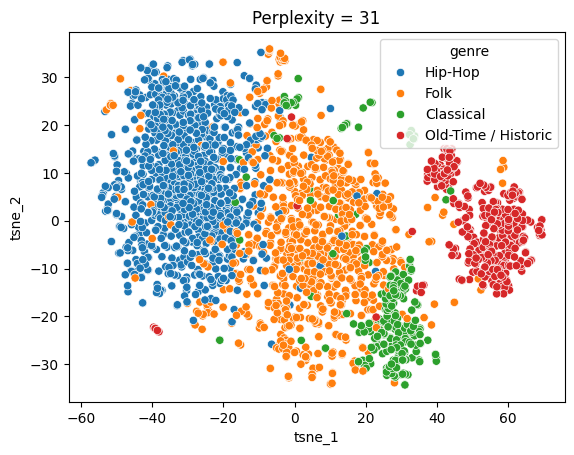

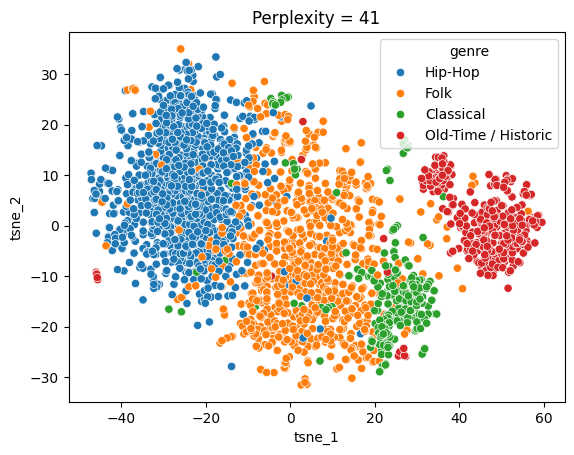

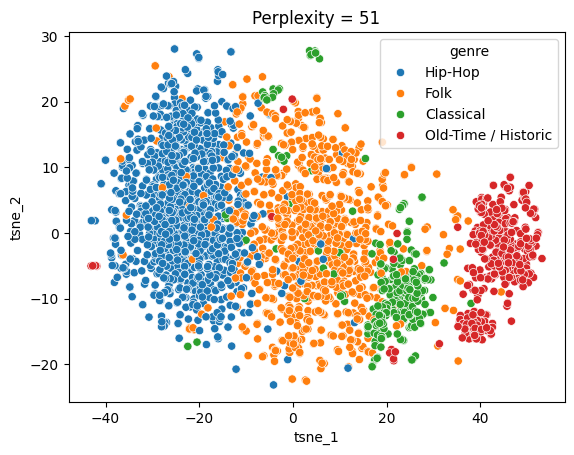

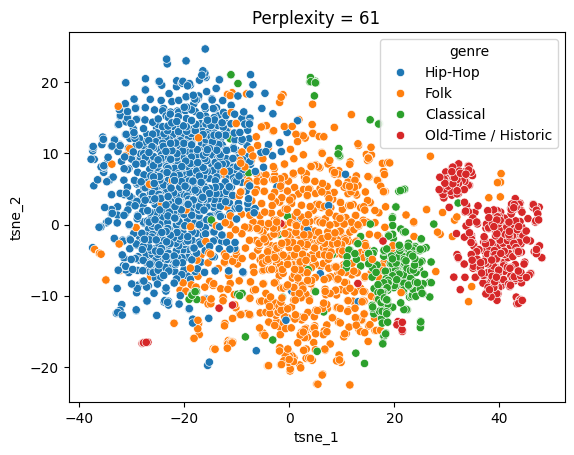

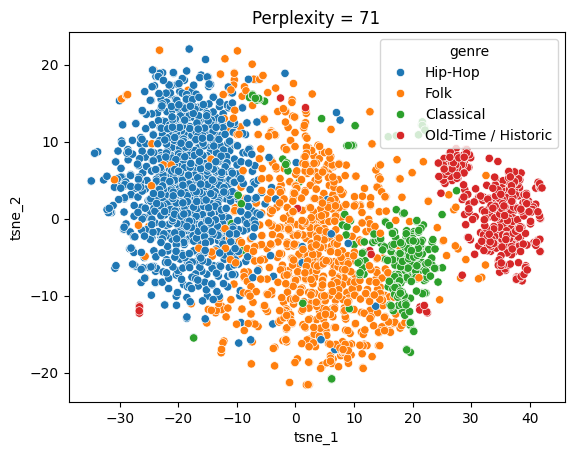

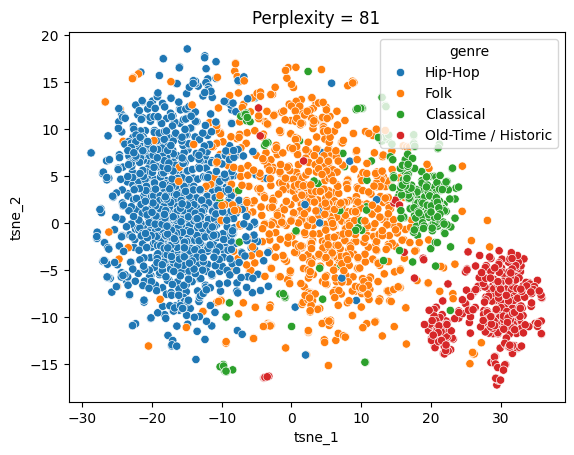

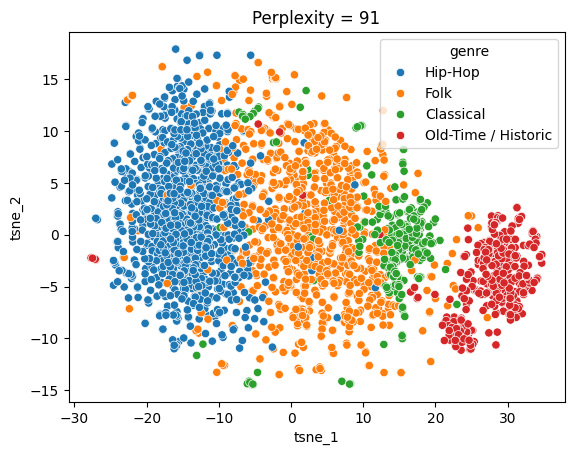

In [27]:
for i in range(1, 100, 10):
    perplexity = i
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42).fit_transform(x_stand_scaled)
    tsne = pd.DataFrame(tsne, columns=['tsne_1', 'tsne_2'])

    sns.scatterplot(x='tsne_1', y='tsne_2', data=tsne, hue=y)
    plt.title('Perplexity = {0}'.format(perplexity))
    plt.show()

# PCA explained variance

In [28]:
display(pca_model.explained_variance_ratio_)
display(np.cumsum(pca_model.explained_variance_ratio_))

array([0.14331656, 0.07309343])

array([0.14331656, 0.21640999])

array([0.14331656, 0.21640999, 0.25799224, 0.29015161, 0.31981846,
       0.3476981 , 0.37521032, 0.39815718, 0.42020781, 0.44118576,
       0.45979925, 0.47780066, 0.49379417, 0.50945364, 0.5233321 ,
       0.53653731, 0.54778831, 0.55867006, 0.56870522, 0.57821365,
       0.58700232, 0.59536482, 0.60326149, 0.61076924, 0.61761115,
       0.62411511, 0.63050932, 0.63660655, 0.64256998, 0.64824787,
       0.65384981, 0.65937845, 0.66465707, 0.66985784, 0.67494909,
       0.67993852, 0.68476212, 0.68943878, 0.69396965, 0.69832497,
       0.70258527, 0.70682314, 0.71083955, 0.71475126, 0.71862377,
       0.72243926, 0.72614803, 0.72978082, 0.73331344, 0.73678189,
       0.74019754, 0.74356567, 0.74685646, 0.75010814, 0.75323894,
       0.75632559, 0.75931146, 0.76228033, 0.76519416, 0.7680897 ,
       0.77093461, 0.77373571, 0.77651322, 0.77925097, 0.78195253,
       0.78461875, 0.78720754, 0.78977704, 0.79226711, 0.79473192,
       0.79718202, 0.79960289, 0.8019829 , 0.80434552, 0.80667

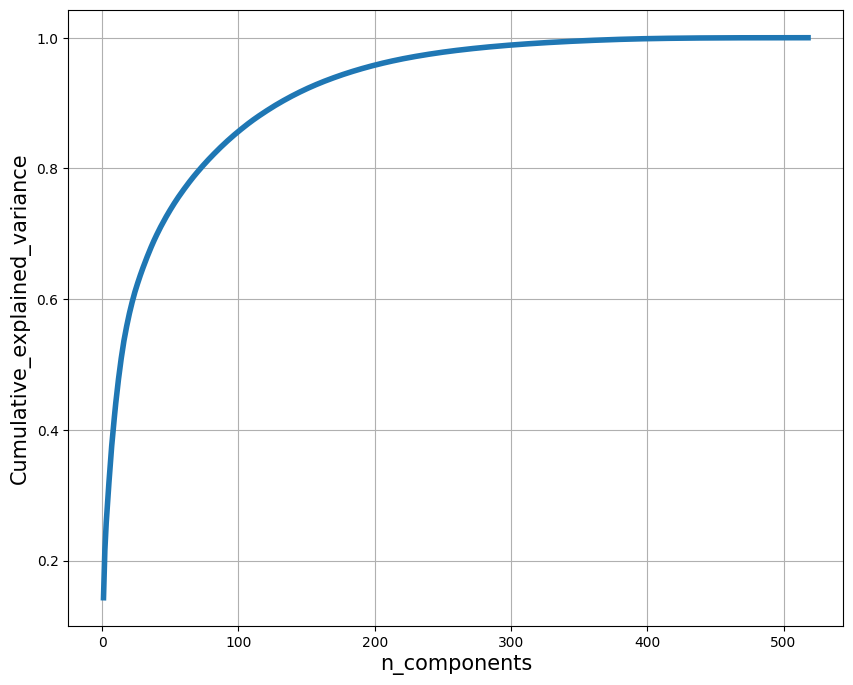

Cumulative dispersion for 2 components: 0.216409990120835
Cumulative dispersion for 518 components: 1.0


In [29]:
pca_model_full = PCA(n_components=518)
pca_full = pca_model_full.fit(x_stand_scaled)
cum_var_explained = np.cumsum(pca_model_full.explained_variance_ratio_)
display(cum_var_explained)

plt.figure(figsize=(10, 8))
#plt.clf()
plt.plot(range(1, len(cum_var_explained) + 1),
         cum_var_explained, linewidth=4)
plt.axis('tight')
plt.grid()
plt.xlabel('n_components', size=15)
plt.ylabel('Cumulative_explained_variance', size=15)
plt.show()

print("Cumulative dispersion for 2 components:", cum_var_explained[1])
print("Cumulative dispersion for 518 components:", cum_var_explained[-1])

# K-means clustering

k = 2, Silhouette Score = 0.1096, Rand Index = 0.6803


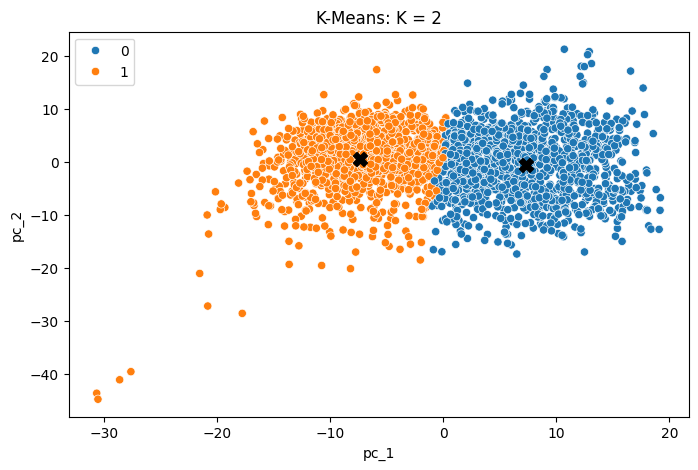

k = 3, Silhouette Score = 0.0899, Rand Index = 0.7856


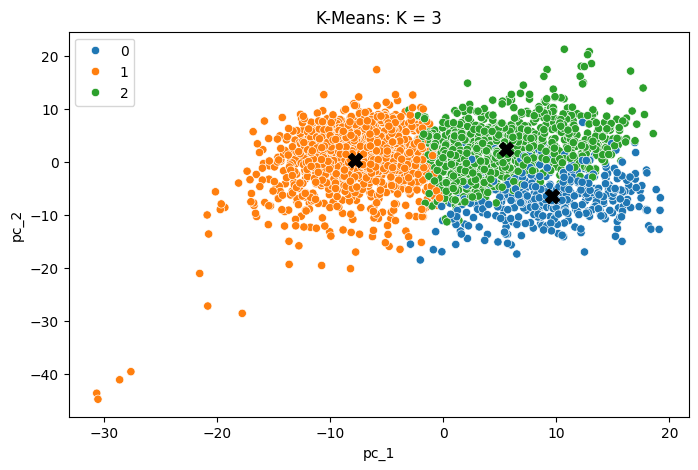

k = 4, Silhouette Score = 0.0756, Rand Index = 0.7740


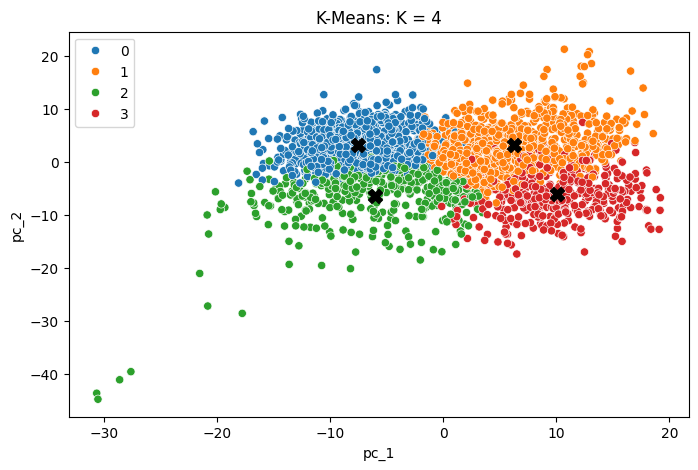

k = 5, Silhouette Score = 0.0718, Rand Index = 0.8047


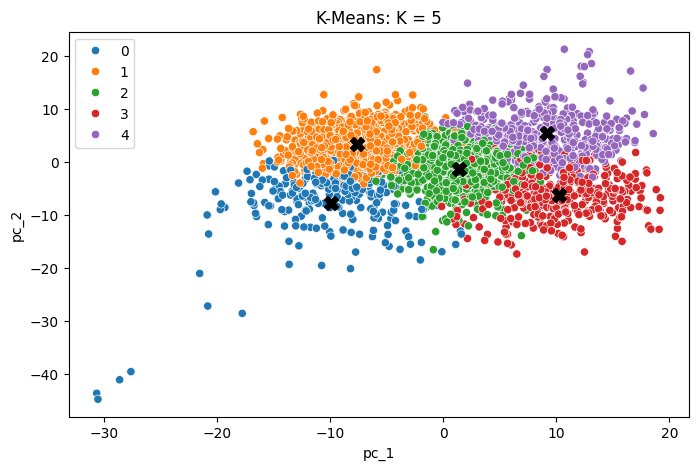

k = 6, Silhouette Score = 0.0721, Rand Index = 0.8048


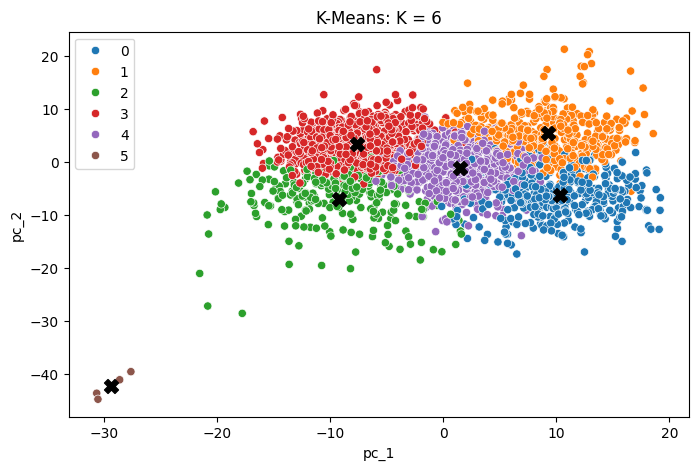

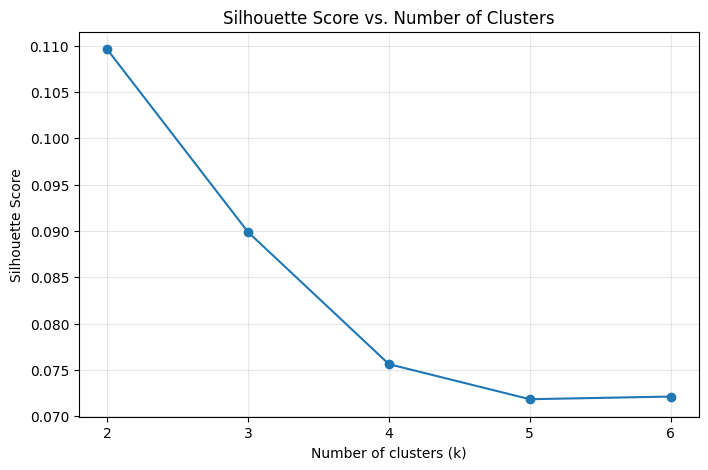

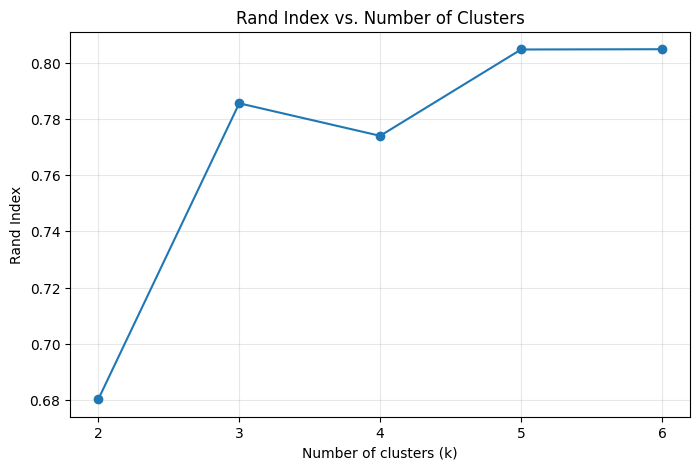

Best K by Silhouette Score: 2
Best K by Rand Index: 6


In [31]:
from sklearn.metrics import silhouette_score, rand_score

k_values = range(2, 7)
silhouette_scores = []
rand_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(x_stand_scaled)

    score = silhouette_score(x_stand_scaled, labels)
    rand_index = rand_score(y, labels)

    silhouette_scores.append(score)
    rand_scores.append(rand_index)

    print(f"k = {k}, Silhouette Score = {score:.4f}, Rand Index = {rand_index:.4f}")

    centers = pca_model.transform(
        pd.DataFrame(kmeans.cluster_centers_,
                     columns=x_stand_scaled.columns)
    )

    plt.figure(figsize=(8, 5))
    sns.scatterplot(x='pc_1', y='pc_2', data=pca,
                    hue=labels, palette='tab10')
    plt.scatter(centers[:, 0], centers[:, 1],
                color='black', marker='X', s=100)
    plt.title(f'K-Means: K = {k}')
    plt.show()

# silhouette
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o')
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.grid(True, alpha=0.3)
plt.show()

# rand index
plt.figure(figsize=(8, 5))
plt.plot(k_values, rand_scores, marker='o')
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Rand Index")
plt.title("Rand Index vs. Number of Clusters")
plt.grid(True, alpha=0.3)
plt.show()
best_k_silhouette = k_values[np.argmax(silhouette_scores)]
best_k_rand = k_values[np.argmax(rand_scores)]

print(f"Best K by Silhouette Score: {best_k_silhouette}")
print(f"Best K by Rand Index: {best_k_rand}")



# Questions
1.  **Whether visualization results from p.3 reflects the real
distribution of the genres? Which algorithm performs better and
why?** - Both PCA and t-SNE reflect the distribution of genres to some extent, but there is still an overlap between them, especially for Folk.
t-SNE provided better visual separation of the genres than PCA, as it is able to capture non-linear relationships between objects and preserve their local similarities. However, neither visualization fully reflects the distribution of genres in the original multidimensional space.
2. **What percentage of the explained variance was left after we
have excluded all but 2 components in p.4?** - First two principal components explain 21.64% of the total variance, 78.36% of the original variance was lost.
3. **Can Silhouette metric be chosen as optimal criteria for the
number of clusters for that data? Is Rand index is more
appropriate?** - According to Silhouette Score, the optimal number of clusters is 2 (0.1096), according to Rand Index it is 6 (0.8048). The Silhouette Score is relatively low for all investigated numbers of clusters, indicating weak cluster separation. Rand Index is more appropriate if the goal is to obtain clusters corresponding to the actual genres. However, it requires knowledge of the original genre labels and cannot be used as an internal clustering evaluation metric.
4. **If you don’t know the genre but need to build a song
recommendation system based on the similarity between the
songs in this dataset - what would you do?** - As there's no information about user's activities, it's gonna be content-based recommendation system. I'd  apply PCA to the scaled dataset, keeping enough principal components to preserve at least 70–80% of the original variance (according to the graph, it can be approached on 40-70 components). It would allow us to reduce dimensionality without losing too much information about the songs (80% variance is initial, further metric depends on user's reaction). Then, I'd use the kNN algorithm with Euclidean distance to find and recommend 5 similar songs to the selected one.
5. **How do you think, what is the most important feature (from the
initial dataset) for the cluster division?** - Let's calculate the variance between cluster centers for each feature for K from 2 to 6. Then, rank the features for each K and calculated their mean ranks to find the features that consistently contribute to cluster separation.


In [34]:
feature_importances = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x_stand_scaled)

    centers = pd.DataFrame(kmeans.cluster_centers_,
                           columns=x_stand_scaled.columns)

    importance = centers.var(axis=0)
    feature_importances[k] = importance

    print(f"K = {k}")
    print(importance.nlargest(3))
    print()

importance_df = pd.DataFrame(feature_importances)

mean_rank = importance_df.rank(ascending=False).mean(axis=1)
print(mean_rank.nsmallest(10))

K = 2
energy            0.961220
mfcc_median_10    0.917611
mfcc_mean_10      0.901598
dtype: float64

K = 3
mfcc_mean_04      1.358690
mfcc_median_04    1.333686
mfcc_max_04       1.290241
dtype: float64

K = 4
mfcc_mean_04      1.145975
mfcc_median_04    1.126527
mfcc_mean_08      1.081843
dtype: float64

K = 5
mfcc_mean_04      1.010502
mfcc_median_04    0.993185
mfcc_mean_08      0.938697
dtype: float64

K = 6
mfcc_kurtosis_01      90.282966
chroma_stft_min_11    83.376009
chroma_stft_min_10    76.672614
dtype: float64

chroma_stft_median_09          40.6
chroma_stft_median_05          42.4
mfcc_max_04                    43.2
spectral_contrast_mean_03      43.2
mfcc_mean_04                   45.0
mfcc_median_04                 45.4
chroma_stft_mean_09            46.0
chroma_stft_median_04          46.0
chroma_stft_median_11          47.2
spectral_contrast_median_03    48.0
dtype: float64


According to the results, **chroma_stft_median_09** has the best mean rank (40.6), while **mfcc_mean_04** shows the highest variance between cluster centers for K = 3, 4 and 5. <br>
**Chroma** (Chromagram) - describes the distribution of energy across 12 musical pitch classes, regardless of octave. <br>
**MFCC** (Mel-Frequency Cepstral Coefficients) describe the spectral envelope of sound, taking into account human auditory perception.